# Productividad por hora trabajada

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"                 # carpeta en research/temas/
GRAFICA_ID = "productividad-hora"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Productividad por hora trabajada"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = 'Dólares PPA por hora, a precios constantes de 2020'  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El producto interior bruto (PIB) por hora trabajada, con la inflación descontada y en dólares con la misma capacidad de compra en todos los países (paridad de poder adquisitivo, PPA). Es la medida más usada de la productividad del trabajo: cuánto se produce, de media, en cada hora de trabajo.

**Cómo se lee.** Un valor mayor significa que cada hora trabajada genera más producción, valorada a los precios y a la capacidad de compra de 2020. Depende del capital, la tecnología, la formación y la organización de las empresas, no del esfuerzo de las personas trabajadoras.

**Limitaciones.**
- Divide por las horas trabajadas de todas las personas ocupadas: un país con menos empleo de baja productividad (por ejemplo, con menos empleo juvenil o de menor cualificación) tiene una productividad media más alta sin que sus empresas sean más productivas.
- El PIB de Irlanda y Luxemburgo está muy influido por las multinacionales y los trabajadores no residentes.
- Las horas trabajadas se estiman a partir de encuestas y fuentes administrativas con métodos distintos según el país.

## 2. Descarga

- **OCDE, base de datos de productividad** (`OECD.SDD.TPS,DSD_PDB@DF_PDB`, versión 2.0): PIB por hora trabajada (`GDPHRS`), total de actividades (`_T`), en dólares PPA por hora (`USD_PPP_H`), a precios constantes con año de referencia 2020 (`LR`, volúmenes encadenados), de España, EE. UU., Canadá, la OCDE y la UE-27 (`EU27_2020`).
- **Código del dataflow:** el config cita `DF_PDB_LV`, que devuelve un error del servidor; se usa `DF_PDB`, su sucesor.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

HOY = date.today().isoformat()
AREAS = {"ESP": "espana", "EU27_2020": "ue27", "OECD": "ocde", "USA": "eeuu", "CAN": "canada"}
DATAFLOW = "OECD.SDD.TPS,DSD_PDB@DF_PDB,2.0"
# Dimensiones: país . frecuencia . medida . actividad . unidad . precios (LR: volumen encadenado, año de referencia)
#              . transformación . activo . conversión (PPA)
CLAVE = "{AREA}.A.GDPHRS._T.USD_PPP_H.LR.N._Z.PPP"

df, fuentes = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
print(df.groupby("serie")["periodo"].agg(["min", "max", "count"]))

         min   max  count
serie                    
canada  1976  2025     50
eeuu    1987  2025     39
espana  1995  2025     31
ocde    1996  2025     30
ue27    1995  2025     31


## 3. Transformación

1. Los valores se usan tal como los publica la OCDE (volúmenes encadenados con 2020 como año de referencia): no hay deflactor propio.
2. La OCDE publica el agregado de la UE-27 (composición actual) para este indicador, así que no hace falta otra fuente.
3. Las notas dejan escrito el año base y qué observaciones marca la fuente como estimadas o con ruptura de serie.

In [ ]:
import io

import requests

from lib._http import pedir

r = pedir(
    requests.Session(), f"{oecd.BASE}/{DATAFLOW}/{CLAVE.replace('{AREA}', '+'.join(AREAS))}", {"startPeriod": str(DESDE)},
    error_cls=oecd.OecdError, etiqueta="productividad por hora (metadatos)", mensaje=lambda r: r.text[:200],
    headers=oecd.CABECERA_CSV,
)
meta = pd.read_csv(io.StringIO(r.text), dtype=str)
assert sorted(meta["BASE_PER"].dropna().unique()) == ["2020"], "El año de referencia ya no es 2020: actualiza UNIDAD y las notas"

NOMBRE = {"ESP": "España", "USA": "Estados Unidos", "CAN": "Canadá", "OECD": "la OCDE", "EU27_2020": "la UE-27"}


def tramos(anios):
    """[1976, 1977, 2024, 2025] -> «de 1976 a 1977 y de 2024 y 2025» (años consecutivos agrupados)."""
    anios, grupos = sorted(set(anios)), []
    for a in anios:
        if grupos and a == grupos[-1][1] + 1:
            grupos[-1][1] = a
        else:
            grupos.append([a, a])
    partes = [str(a) if a == b else f"{a}" + (" y " if b == a + 1 else " a ") + f"{b}" for a, b in grupos]
    partes = [("de " + p if " " in p else p) for p in partes]
    return partes[0] if len(partes) == 1 else ", ".join(partes[:-1]) + " y " + partes[-1]


def marcas(estado):
    m = meta[meta["OBS_STATUS"] == estado]
    return {NOMBRE[a]: tramos(g["TIME_PERIOD"].astype(int)) for a, g in m.groupby("REF_AREA")}


estimadas = {k: v for k, v in marcas("E").items() if k not in ("la OCDE", "la UE-27")}
provisionales = marcas("P")
NOTAS = [
    f"OCDE, base de datos de productividad ({DATAFLOW.split(',')[1]}, versión 2.0): PIB por hora trabajada (GDPHRS), "
    "total de actividades, en dólares estadounidenses PPA, en volúmenes encadenados con 2020 como año de referencia.",
    "UE-27: agregado de composición actual (EU27_2020) publicado por la OCDE. OCDE: agregado publicado por la OCDE.",
    "Las horas trabajadas se estiman con encuestas y fuentes administrativas que difieren entre países.",
]
if estimadas:
    lista = [f"{k} ({v})" for k, v in estimadas.items()]
    NOTAS.append(
        "La OCDE marca como estimados los datos de " + (lista[0] if len(lista) == 1 else ", ".join(lista[:-1]) + " y " + lista[-1])
        + ": pueden revisarse en las próximas ediciones."
    )
if provisionales:
    lista = [f"{k} ({v})" for k, v in provisionales.items()]
    NOTAS.append(
        "La OCDE marca como provisionales los datos de " + (lista[0] if len(lista) == 1 else ", ".join(lista[:-1]) + " y " + lista[-1]) + "."
    )

## 4. Visualización

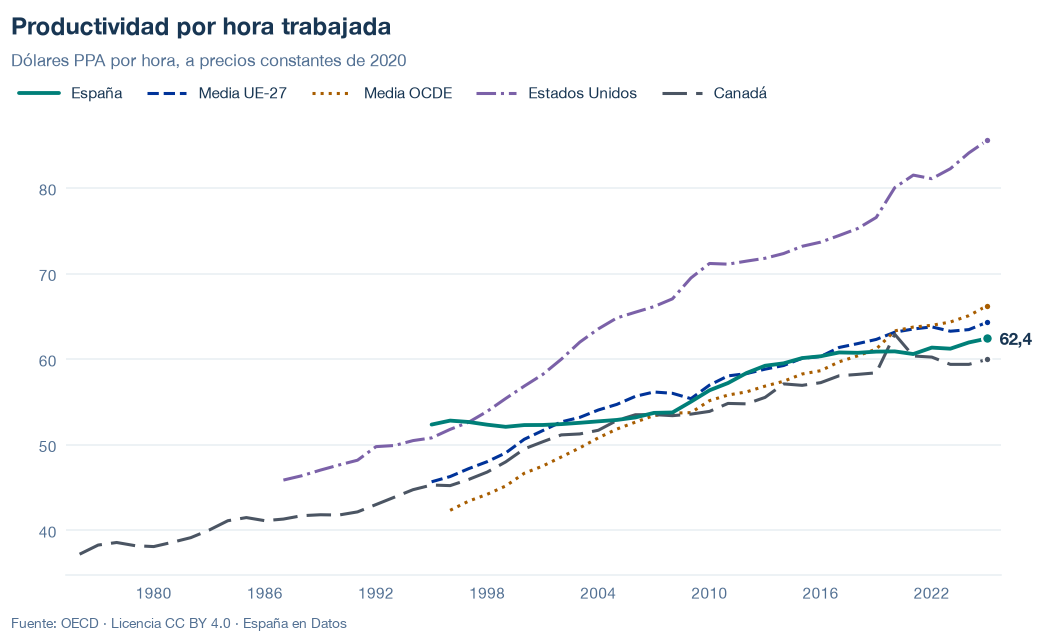

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/productividad-hora.json y data/productividad-hora.csv


## 6. Fuentes, notas y licencia

- OCDE, base de datos de productividad: `OECD.SDD.TPS,DSD_PDB@DF_PDB,2.0` (`GDPHRS`, `_T`, `USD_PPP_H`, `LR`, `N`, `_Z`, `PPP`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.